# Descarga Datos CMIP6

![cmip6_logo-01](cmip6_logo-01.jpg)

En este notebook vamos a ver cómo descargar datos de modelos acoplados incluidos en el proyecto de intercomparación CMIP6.
Además, en un siguiente notebook veremos su contenido, haremos un pequeño preprocesamiento, y visualizaremos datos de temperatura superficial de los mismos.  

Vamos a usar un API para descargar los datos, y xarray para visualizarlo:
1. [`Xarray`](https://docs.xarray.dev/en/stable/index.html#).

Usaremos `Xarray` como en ocasiones anteriores ya que tenemos datos en 3 o más dimensiones.

In [10]:
from matplotlib import pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

xr.set_options(display_style='html')
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

In [11]:
import requests


def esgf_search(
    server="https://esgf-data.dkrz.de/esg-search/search",
    files_type="OPENDAP",
    local_node=False,
    project="CMIP6",
    verbose=False,
    format="application%2Fsolr%2Bjson",
    use_csrf=False,
    **search,
):
  # Lista de nodos activos en ambos dominios (Europa y EE. UU.)
  servers = [
      server,
      "https://esgf.ceda.ac.uk/esg-search/search",
      "https://esgf-node.ornl.gov/esgf-1-5-bridge",
  ]
  # Eliminar duplicados manteniendo el orden
  servers = list(dict.fromkeys(servers))

  files_type = files_type.upper()

  for srv in servers:
    client = requests.session()
    payload = search.copy()
    payload["project"] = project
    payload["type"] = "File"
    payload["distrib"] = "false" if local_node else "true"
    payload["format"] = format

    try:
      if use_csrf:
        client.get(srv, timeout=15)
        csrftoken = client.cookies.get("csrftoken") or client.cookies.get(
            "csrf"
        )
        if csrftoken:
          payload["csrfmiddlewaretoken"] = csrftoken

      offset = 0
      numFound = 10000
      all_files = []

      while offset < numFound:
        payload["offset"] = offset
        url_keys = ["{}={}".format(k, payload[k]) for k in payload]
        url = "{}?{}".format(srv, "&".join(url_keys))
        if verbose:
          print("Consultando:", url)

        r = client.get(url, timeout=30)
        r.raise_for_status()
        resp = r.json()["response"]
        numFound = int(resp["numFound"])
        docs = resp["docs"]

        if not docs:
          break

        offset += len(docs)
        for d in docs:
          if verbose:
            for k in d:
              print("{}: {}".format(k, d[k]))
          for f in d.get("url", []):
            sp = f.split("|")
            if sp[-1].upper() == files_type:
              all_files.append(sp[0].split(".html")[0])

      if all_files:
        return sorted(all_files)

    except Exception as e:
      if verbose:
        print(f"Fallo en {srv}: {e}")
      continue

  return []


In [12]:
# Este API nos permite filtrar nuestra búsqueda atendiendo a la variable, el experimento, la institución que está a cargo de la simulacion, etc
result = esgf_search(activity_id='CMIP', table_id='Omon', variable_id='tos', 
                     experiment_id='historical',grid_label='gn',
                     source_id="CNRM-ESM2-1", member_id="r1i1p1f2")
result

['http://esg1.umr-cnrm.fr/thredds/dodsC/CMIP6_CNRM/CMIP/CNRM-CERFACS/CNRM-ESM2-1/historical/r1i1p1f2/Omon/tos/gn/v20181206/tos_Omon_CNRM-ESM2-1_historical_r1i1p1f2_gn_185001-201412.nc',
 'http://esgf3.dkrz.de/thredds/dodsC/cmip6/CMIP/CNRM-CERFACS/CNRM-ESM2-1/historical/r1i1p1f2/Omon/tos/gn/v20181206/tos_Omon_CNRM-ESM2-1_historical_r1i1p1f2_gn_185001-201412.nc',
 'https://esgf.ceda.ac.uk/thredds/dodsC/esg_cmip6/CMIP6/CMIP/CNRM-CERFACS/CNRM-ESM2-1/historical/r1i1p1f2/Omon/tos/gn/v20181206/tos_Omon_CNRM-ESM2-1_historical_r1i1p1f2_gn_185001-201412.nc']

In [13]:
# Como vemos hay diferentes fuentes para el mismo archivo, así que usaremos una de ellas
files_to_open = result[-1:] # con esto abro la última listada
# Abrimos el archivo usando la función de archivos múltiples de xarray
ds = xr.open_mfdataset(files_to_open, combine='by_coords')
ds

<xarray.Dataset> Size: 851MB
Dimensions:      (y: 294, x: 362, nvertex: 4, time: 1980, axis_nbounds: 2)
Coordinates:
    lat          (y, x) float64 851kB dask.array<chunksize=(294, 362), meta=np.ndarray>
    lon          (y, x) float64 851kB dask.array<chunksize=(294, 362), meta=np.ndarray>
  * time         (time) datetime64[ns] 16kB 1850-01-16T12:00:00 ... 2014-12-1...
Dimensions without coordinates: y, x, nvertex, axis_nbounds
Data variables:
    bounds_lon   (y, x, nvertex) float64 3MB dask.array<chunksize=(294, 362, 4), meta=np.ndarray>
    bounds_lat   (y, x, nvertex) float64 3MB dask.array<chunksize=(294, 362, 4), meta=np.ndarray>
    time_bounds  (time, axis_nbounds) datetime64[ns] 32kB dask.array<chunksize=(1980, 2), meta=np.ndarray>
    tos          (time, y, x) float32 843MB dask.array<chunksize=(1980, 294, 362), meta=np.ndarray>
Attributes: (12/53)
    Conventions:                     CF-1.7 CMIP-6.2
    creation_date:                   2018-09-15T06:43:44Z
    description:                     CMIP6 historical
    title:                           CNRM-ESM2-1 model output prepared for CM...
    activity_id:                     CMIP
    contact:                         contact.cmip@meteo.fr
    ...                              ...
    xios_commit:                     1442-shuffle
    nemo_gelato_commit:              49095b3accd5d4c_6524fe19b00467a
    arpege_minor_version:            6.3.2
    history:                         none
    tracking_id:                     hdl:21.14100/74ad1b1d-8ec9-4010-b51a-86f...
    DODS_EXTRA.Unlimited_Dimension:  time

In [14]:
ds.tos

<xarray.DataArray 'tos' (time: 1980, y: 294, x: 362)> Size: 843MB
dask.array<open_dataset-tos, shape=(1980, 294, 362), dtype=float32, chunksize=(1980, 294, 362), chunktype=numpy.ndarray>
Coordinates:
  * time     (time) datetime64[ns] 16kB 1850-01-16T12:00:00 ... 2014-12-16T12...
    lat      (y, x) float64 851kB dask.array<chunksize=(294, 362), meta=np.ndarray>
    lon      (y, x) float64 851kB dask.array<chunksize=(294, 362), meta=np.ndarray>
Dimensions without coordinates: y, x
Attributes:
    standard_name:       sea_surface_temperature
    long_name:           Sea Surface Temperature
    units:               degC
    online_operation:    average
    cell_methods:        area: mean where sea time: mean
    interval_operation:  1800 s
    interval_write:      1 month
    description:         This may differ from "surface temperature" in region...
    history:             none
    cell_measures:       area: areacello
    _ChunkSizes:         [  1 294 362]

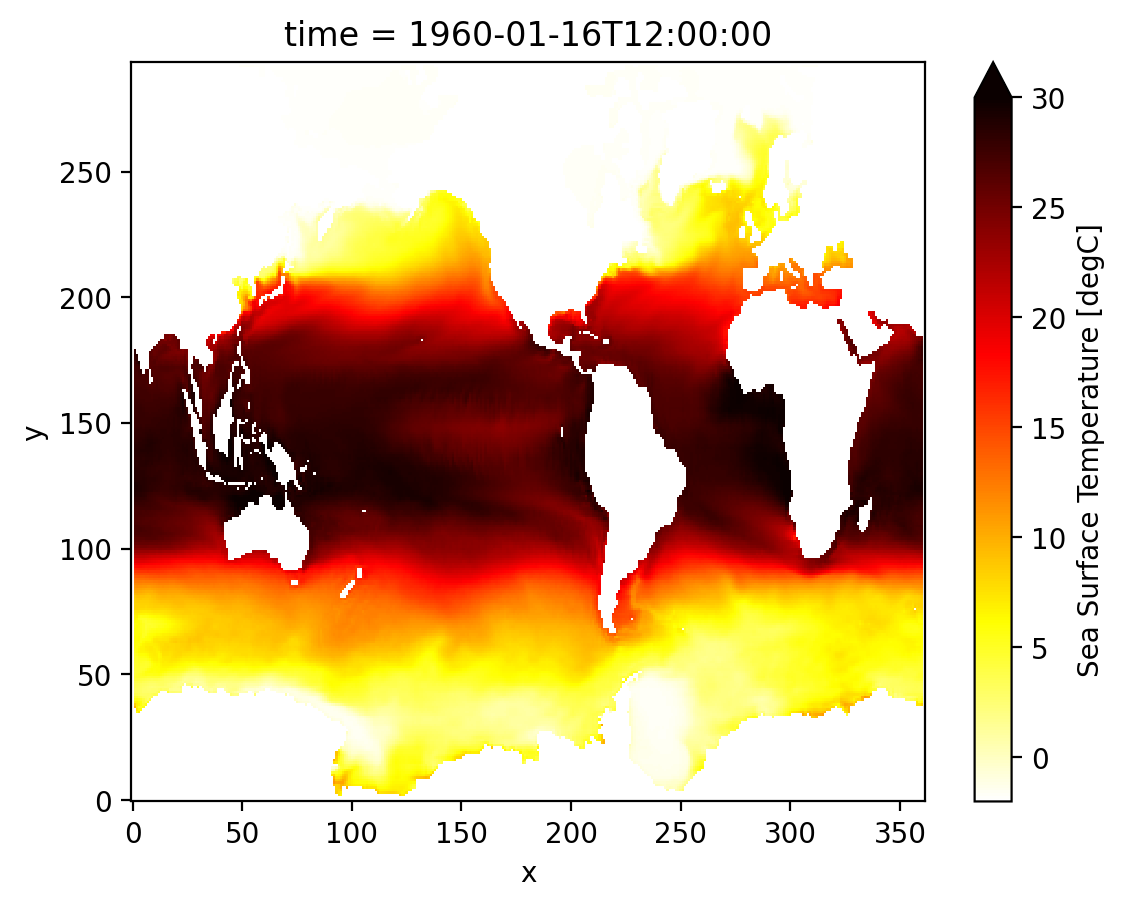

In [15]:
ds.tos.sel(time='1960-01').squeeze().plot(vmin=-2, vmax=30, cmap='hot_r')

In [19]:
# Extraemos automáticamente el grid_label y variant_label de tu archivo tos
malla_tos = ds.tos.attrs.get("grid_label", "gn")
variante_tos = ds.tos.attrs.get("variant_label", "r1i1p1f2")

files_area = esgf_search(
    variable_id="areacello",
    activity_id="CMIP",
    experiment_id="piControl",
    source_id="CNRM-ESM2-1",
    grid_label=malla_tos,
    variant_label=variante_tos,
)

print("Archivos filtrados:", files_area)
ds_area = xr.open_dataset(files_area[-1])


Archivos filtrados: ['http://esg1.umr-cnrm.fr/thredds/dodsC/CMIP6_CNRM/CMIP/CNRM-CERFACS/CNRM-ESM2-1/piControl/r1i1p1f2/Ofx/areacello/gn/v20181115/areacello_Ofx_CNRM-ESM2-1_piControl_r1i1p1f2_gn.nc', 'http://esgf3.dkrz.de/thredds/dodsC/cmip6/CMIP/CNRM-CERFACS/CNRM-ESM2-1/piControl/r1i1p1f2/Ofx/areacello/gn/v20181115/areacello_Ofx_CNRM-ESM2-1_piControl_r1i1p1f2_gn.nc', 'https://esgf.ceda.ac.uk/thredds/dodsC/esg_cmip6/CMIP6/CMIP/CNRM-CERFACS/CNRM-ESM2-1/piControl/r1i1p1f2/Ofx/areacello/gn/v20181115/areacello_Ofx_CNRM-ESM2-1_piControl_r1i1p1f2_gn.nc']


In [17]:
ds_area = xr.open_dataset(files_area[-1],)
ds_area


<xarray.Dataset> Size: 9MB
Dimensions:     (y: 294, x: 362, nvertex: 4)
Coordinates:
    lat         (y, x) float64 851kB ...
    lon         (y, x) float64 851kB ...
Dimensions without coordinates: y, x, nvertex
Data variables:
    bounds_lon  (y, x, nvertex) float64 3MB ...
    bounds_lat  (y, x, nvertex) float64 3MB ...
    areacello   (y, x) float32 426kB ...
Attributes: (12/55)
    Conventions:                     CF-1.7 CMIP-6.2
    creation_date:                   2018-08-31T01:08:55Z
    description:                     DECK: control
    title:                           CNRM-ESM2-1 model output prepared for CM...
    activity_id:                     CMIP
    contact:                         contact.cmip@meteo.fr
    ...                              ...
    arpege_minor_version:            6.3.1
    history:                         none
    tracking_id:                     hdl:21.14100/76e46da0-2b2c-4e24-975d-b8c...
    DODS_EXTRA.Unlimited_Dimension:  time
    EXTRA_DIMENSION.axis_nbounds:    2
    EXTRA_DIMENSION.time:            0

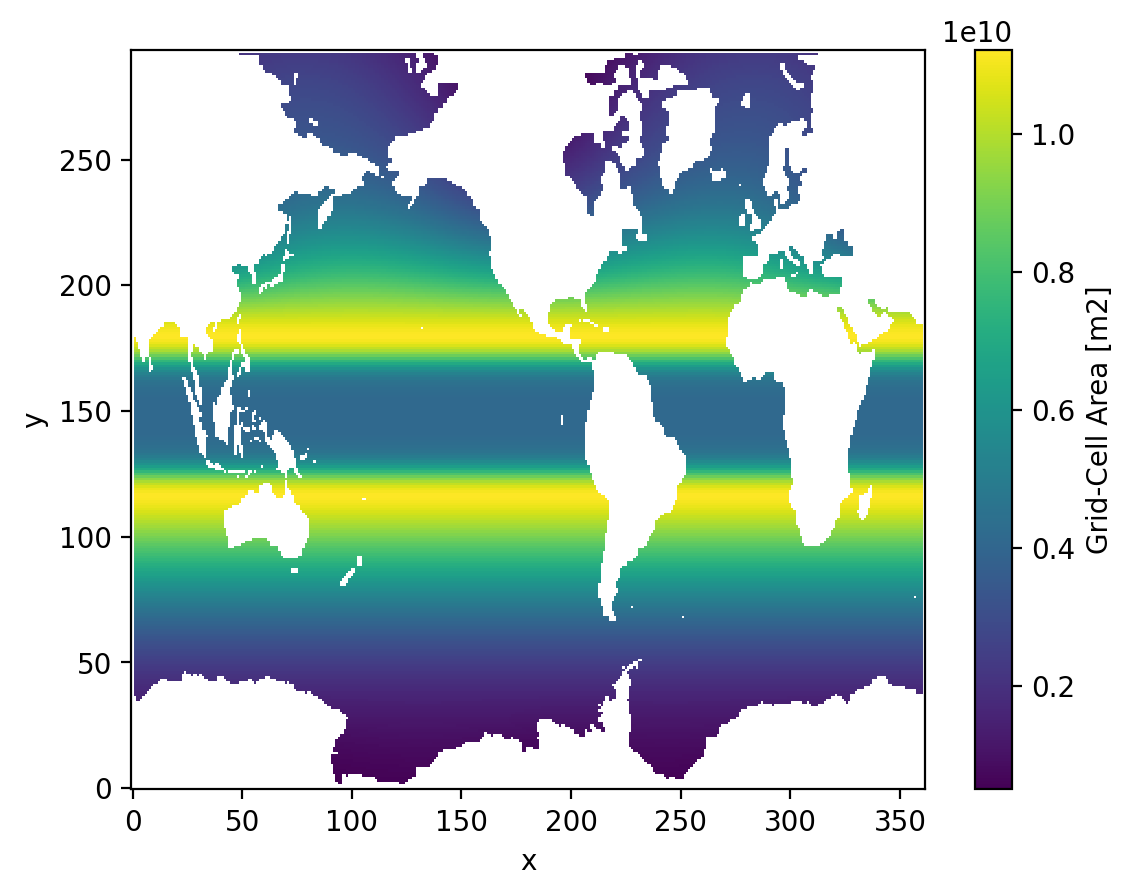

In [18]:
ds_area.areacello.squeeze().plot()